# IMED kinetic validation against QMOM

## Summary

The saved run covers 20 synthetic kinetic cases at two PBM tolerance settings. All 20 met the 1 ppm API balance limit at both settings. At IMED defaults, the largest PBM inventory error was **5.33 × 10⁻¹⁵ g** on a 7.61 g API charge.

**19 of 20** met the full QMOM comparison criteria. Among those 19, the largest moment error was **0.899%** at default tolerances and **0.630%** at tighter tolerances. K17 conserved API and exceeded the M5 agreement limit. A follow-up at one-tenth its original agglomeration rate passed.

Run the notebook offline from the repository to reproduce these results or change the controls below.

## Method and setup

The sweep calls IMED's production [conservative PBM](solver.py) and the independent [three-node QMOM](validation/qmom.py) through the [validation runner](validation/kinetics_sweep.py). Each pair uses the same 60-second profile, seed, solubility, kinetics and 100 sample times. The operating profiles cover cooling, antisolvent addition, and their combination.

The API inventory includes dissolved API, crystal mass on the mesh, and crystal mass transported past the PBM size cutoff. The initial API charge is calculated from the seed and starting solution. Peak trajectory errors divide the largest absolute PBM–QMOM difference by the peak absolute QMOM value for that quantity. M0 is particle number and M3 is proportional to resolved crystal volume. M5 is particularly sensitive to large crystals.

Use a Python kernel with NumPy, SciPy, pandas, Jinja2 and Matplotlib. Open the notebook from the repository root or a folder inside it.

In [1]:
import os
import sys
from contextlib import redirect_stdout
from dataclasses import asdict, replace
from io import StringIO
from pathlib import Path

# The validation matrices are small enough to use one BLAS thread.
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

shell = get_ipython()
if shell is not None:
    shell.run_line_magic("matplotlib", "inline")

repo_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "imed_python" / "validation" / "kinetics_sweep.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Start Jupyter in the Orhcestrator repository or one of its subfolders.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from imed_python.validation.kinetics_sweep import CASES, LIMITS, MASS_LIMIT, MOMENTS, run_case

plt.rcParams.update({
    "axes.grid": True, "axes.axisbelow": True, "grid.alpha": 0.23,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})

## Inputs

Edit the controls below and rerun from this cell. The rates are on a linear scale. Keep `kg` positive. Set `kp`, `ks`, `ka`, `kbr` or `kd` to zero to disable that term. The rate units depend on the kinetic law and kernel. The validation profiles include a late reheat or dilution stage that can activate breakage after agglomerates form.

For a quick single-case run, set `case_ids` and set `run_k17_followups = False`. The complete per-mode results and time series are available as `results` and `trajectories`.

In [17]:
# Set to ["K17"] or another list to run a subset. None selects all 20.
case_ids = None
pbm_modes = ("IMED defaults", "Tight benchmark")
bin_count = 250
length_max_override_um = None
detail_case_id = "K20"
run_k17_followups = True

# Example: {"K17": {"ka": 4e-13, "kp": 8000, "kbr": 0.15}}
kinetic_overrides = {}

tolerances = {"IMED defaults": True, "Tight benchmark": False}
case_library = dict(CASES)
selected_ids = list(case_library) if case_ids is None else list(case_ids)
unknown_ids = (set(selected_ids) | set(kinetic_overrides)) - set(case_library)
if unknown_ids:
    raise ValueError(f"Unknown case IDs {sorted(unknown_ids)}")
if not selected_ids or len(set(selected_ids)) != len(selected_ids):
    raise ValueError("Select at least one case and use each case ID once.")
if not pbm_modes or len(set(pbm_modes)) != len(pbm_modes) or set(pbm_modes) - set(tolerances):
    raise ValueError(f"Select one or both PBM modes from {list(tolerances)}.")

selected_cases = {}
for case_id in selected_ids:
    overrides = dict(kinetic_overrides.get(case_id, {}))
    if length_max_override_um is not None:
        overrides["length_max"] = length_max_override_um
    selected_cases[case_id] = replace(case_library[case_id], **overrides)

inputs = pd.DataFrame.from_dict(
    {case_id: asdict(kinetics) for case_id, kinetics in selected_cases.items()}, orient="index",
)
input_columns = ["profile", "kg", "kp", "ks", "ka", "kbr", "kd", "kernel", "length_max"]
input_table = inputs[input_columns].rename(columns={"length_max": "Lmax (µm)"})
rate_format = {column: "{:.3g}" for column in ("kg", "kp", "ks", "ka", "kbr", "kd")}
display(input_table.style.format(rate_format | {"Lmax (µm)": "{:g}"}))

,profile,kg,kp,ks,ka,kbr,kd,kernel,Lmax (µm)
K01,combined,0.65,2e+03,5e+05,5e-08,0.12,0,1,65
K02,combined,0.65,6e+04,5e+05,5e-08,0.12,0,1,65
K03,combined,0.65,1.3e+04,5e+04,5e-08,0.12,0,1,65
K04,combined,0.65,1.3e+04,3e+06,5e-08,0.12,0,1,65
K05,combined,0.65,1.3e+04,5e+05,8e-09,0.12,0,1,65
K06,combined,0.65,1.3e+04,5e+05,4e-07,0.12,0,1,65
K07,combined,0.65,1.3e+04,5e+05,5e-08,0.015,0,1,65
K08,combined,0.65,1.3e+04,5e+05,5e-08,0.6,0,1,65
K09,cooling,0.45,0,0,0,0,0,1,65
K10,cooling,0.9,3e+04,0,0,0,0.02,1,65


## Run the comparisons

IMED defaults use a relative tolerance of 10⁻³ and an absolute tolerance of 10⁻⁶. The tight benchmark uses 5 × 10⁻⁷ and 10⁻⁸, with a 0.6 s maximum step. Both modes use the same QMOM refinement check. The full run can take a few minutes.

A solver error means a comparison could not be computed. A failed comparison means both solvers returned data and at least one acceptance check failed.

In [33]:
selected_cases["K08"]

Kinetics(profile='combined', kg=0.65, kp=13000.0, ks=500000.0, ka=5e-08, kbr=0.6, kernel=1, growth_size_factor=0.0, aggregation_growth_power=0.0, breakage_volume_power=0.0, kd=0.0, daughter_center=1400.0, daughter_width=360.0, secondary_moment=0, length_max=65.0)

In [9]:
moment_columns = [f"{name}_error_pct" for name in MOMENTS]
records, histories, solver_errors = [], [], []

def evaluate(case_id, kinetics, bins, mode):
    # The CLI also prints these checks. The notebook displays them as tables.
    with redirect_stdout(StringIO()):
        rows, trace = run_case(case_id, kinetics, [bins], app_tolerances=tolerances[mode])
    row = dict(rows[0], mode=mode)
    row["max_moment_error_pct"] = max(row[column] for column in moment_columns)
    return row, pd.DataFrame(trace).assign(mode=mode)

for case_id, kinetics in selected_cases.items():
    for mode in pbm_modes:
        try:
            row, history = evaluate(case_id, kinetics, bin_count, mode)
        except (ValueError, RuntimeError, TimeoutError, FloatingPointError) as error:
            solver_errors.append({"case": case_id, "mode": mode, "error": str(error)})
        else:
            records.append(row)
            histories.append(history)

if solver_errors:
    display(pd.DataFrame(solver_errors))
if not records:
    raise RuntimeError("No selected case and mode completed. Review the solver errors above.")

results = pd.DataFrame(records)
trajectories = pd.concat(histories, ignore_index=True)
overview = results.groupby("mode", sort=False).agg(
    completed=("case", "size"),
    mass_balance_passes=("mass_passed", "sum"),
    full_passes=("status", lambda statuses: statuses.eq("PASS").sum()),
    worst_PBM_balance_g=("pbm_mass_error_g", "max"),
    worst_QMOM_balance_g=("qmom_mass_error_g", "max"),
)
overview.insert(0, "requested", len(selected_cases))
display(overview.style.format(precision=0, formatter={
    "worst_PBM_balance_g": "{:.3e}", "worst_QMOM_balance_g": "{:.3e}",
}))

,requested,completed,mass_balance_passes,full_passes,worst_PBM_balance_g,worst_QMOM_balance_g
mode,,,,,,
IMED defaults,20,20,20,19,5.329e-15,1.776e-14
Tight benchmark,20,20,20,19,1.776e-14,1.776e-14


### Errors by case

Both solvers must conserve API to within 1 ppm. Full comparison also checks the six moments, particle count per liquid volume, mean size, concentration, dissolved API, positivity, mechanism activity, off-grid mass and QMOM time refinement. The moment limits are 2.5% for M0–M3, 4% for M4 and 5% for M5. The concentration limit is 0.1%.

In [10]:
case_columns = {
    "max_moment_error_pct": "Worst moment (%)",
    "M3_error_pct": "M3 (%)",
    "M5_error_pct": "M5 (%)",
    "concentration_error_pct": "Concentration (%)",
    "pbm_mass_error_g": "PBM balance (g)",
    "pbm_overflow_g": "Off-grid solid (g)",
    "mass_passed": "API balance",
    "status": "Full check",
}
per_case = results.set_index(["case", "mode"])[list(case_columns)].rename(columns=case_columns)
display(per_case.style.format(precision=3, formatter={
    "PBM balance (g)": "{:.2e}", "Off-grid solid (g)": "{:.2e}",
    "API balance": lambda passed: "PASS" if passed else "FAIL",
}))

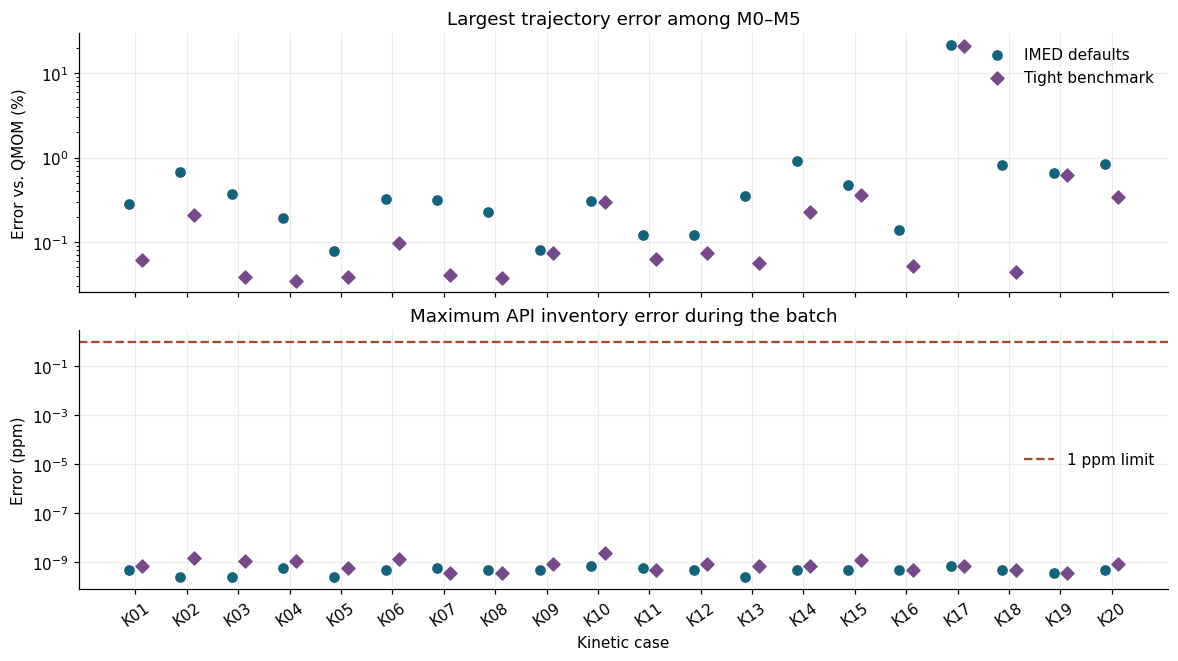

In [11]:
fig, (error_axis, balance_axis) = plt.subplots(
    2, 1, figsize=(10.6, 5.9), sharex=True, layout="constrained",
)
positions = dict(zip(selected_ids, range(len(selected_ids))))
markers = {"IMED defaults": ("o", "#12637b"), "Tight benchmark": ("D", "#76498a")}
for mode, rows in results.groupby("mode", sort=False):
    x = rows["case"].map(positions)
    marker, color = markers[mode]
    offset = 0 if len(pbm_modes) == 1 else (-0.13 if tolerances[mode] else 0.13)
    error_axis.scatter(x + offset, rows["max_moment_error_pct"],
                       marker=marker, color=color, label=mode)
    # Display zero residuals at the floating-point scale for this logarithmic axis.
    ppm = np.maximum(rows["pbm_mass_error_ppm"], np.finfo(float).eps * 1e6)
    balance_axis.scatter(x + offset, ppm, marker=marker, color=color)

error_axis.set(title="Largest trajectory error among M0–M5", ylabel="Error vs. QMOM (%)")
balance_axis.set(title="Maximum API inventory error during the batch", ylabel="Error (ppm)",
                 xlabel="Kinetic case")
balance_axis.axhline(MASS_LIMIT * 1e6, color="#a34b2c", ls="--", label="1 ppm limit")
balance_axis.set_xticks(list(positions.values()), list(positions), rotation=35)
for axis in (error_axis, balance_axis):
    axis.set_yscale("log")
    axis.legend(loc="best", frameon=False)
plt.show()

### Inspect one batch

The batch plot compares dissolved, resolved solid and total API, along with particle number, resolved crystal volume and number-weighted mean size. PBM total API includes off-grid solid. Three-node QMOM has no outflow state. The balance panel uses signed residuals from the same input charge.

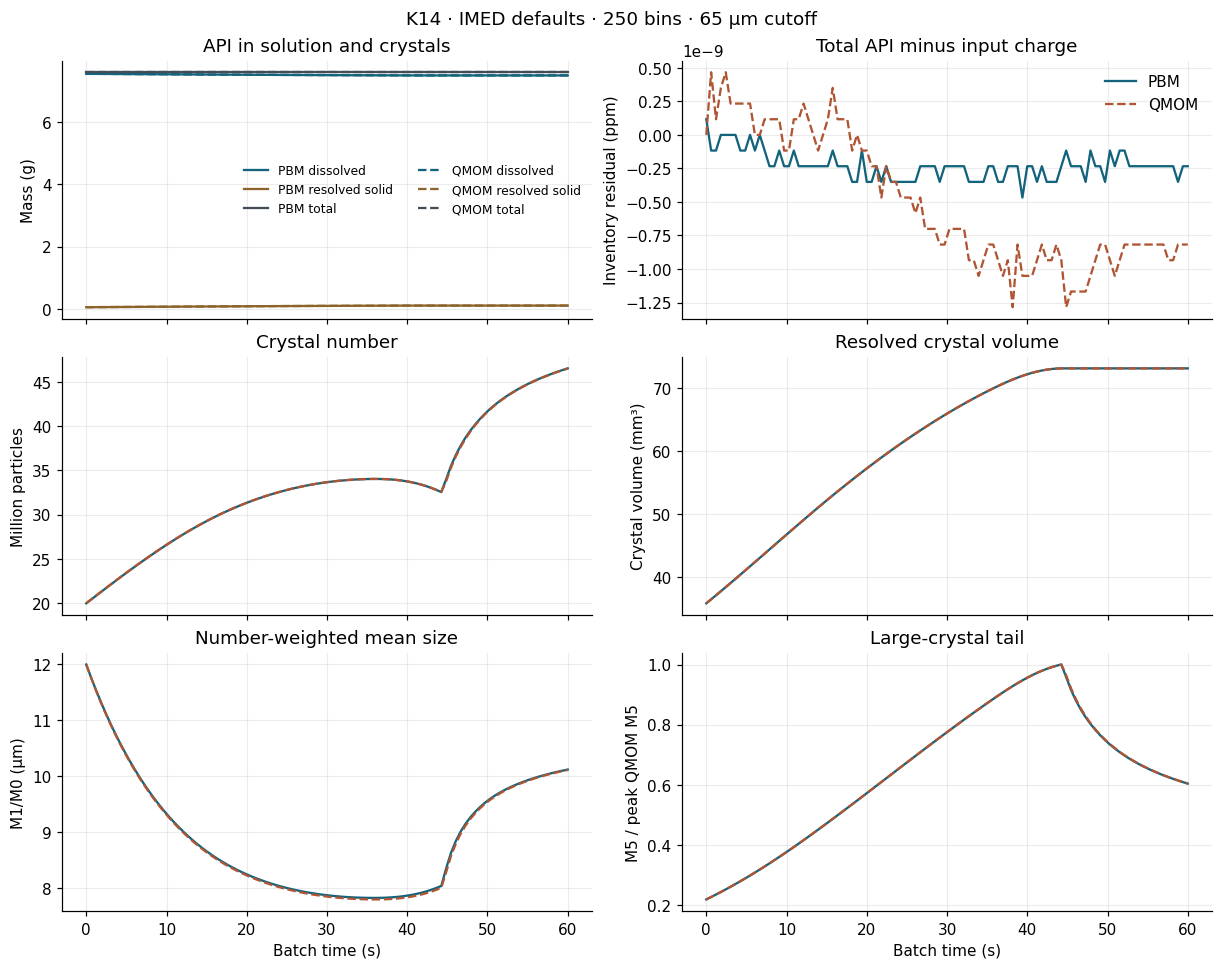

,Error (%),Limit (%)
Metric,,
M0,0.4995,2.5000
M1,0.8991,2.5000
M2,0.4428,2.5000
M3,0.0057,2.5000
M4,0.4007,4.0000
M5,0.6167,5.0000
count,0.5681,2.5000
mean_size,0.5647,2.5000
concentration,0.0115,0.1000


PBM off-grid solid at the end of the batch = 1.850e-42 g


In [34]:
detail_case_id = "K14"
available_cases = results["case"].unique()
shown_case = detail_case_id if detail_case_id in available_cases else available_cases[0]
detail = results[results["case"].eq(shown_case)].iloc[0]
trace = trajectories[
    trajectories["case"].eq(shown_case) & trajectories["mode"].eq(detail["mode"])
]
_, _, process, _, _ = selected_cases[shown_case].inputs(bin_count)
shape = process["ShapeFactor"]

fig, axes = plt.subplots(3, 2, figsize=(11, 8.7), sharex=True, layout="constrained")
fig.suptitle(f"{shown_case} · {detail['mode']} · {detail['cells']} bins · {detail['length_max']:g} µm cutoff")
mass_axis, balance_axis, number_axis, volume_axis, size_axis, tail_axis = axes.flat
for method, label, style, color in (
    ("pbm", "PBM", "-", "#12637b"), ("qmom", "QMOM", "--", "#b05533"),
):
    time = trace["time_s"]
    dissolved = trace[f"dissolved_g_{method}"]
    crystal = trace[f"crystal_g_{method}"]
    overflow = trace[f"overflow_g_{method}"]
    for values, name, component_color in (
        (dissolved, "dissolved", "#12637b"),
        (crystal, "resolved solid", "#8c632a"),
        (dissolved + crystal + overflow, "total", "#444c55"),
    ):
        mass_axis.plot(time, values, style, color=component_color, label=f"{label} {name}")
    ppm = trace[f"{method}_inventory_error_g"] / detail["initial_api_g"] * 1e6
    balance_axis.plot(time, ppm, style, color=color, label=label)
    number_axis.plot(time, trace[f"M0_{method}"] / 1e6, style, color=color)
    volume_axis.plot(time, shape * trace[f"M3_{method}"] / 1e9, style, color=color)
    size_axis.plot(time, trace[f"mean_size_{method}"], style, color=color)
    tail_axis.plot(time, trace[f"M5_{method}"] / trace["M5_qmom"].max(), style, color=color)

mass_axis.set(title="API in solution and crystals", ylabel="Mass (g)")
mass_axis.legend(frameon=False, ncol=2, fontsize=8)
balance_axis.set(title="Total API minus input charge", ylabel="Inventory residual (ppm)")
balance_axis.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3))
balance_axis.legend(frameon=False)
number_axis.set(title="Crystal number", ylabel="Million particles")
volume_axis.set(title="Resolved crystal volume", ylabel="Crystal volume (mm³)")
size_axis.set(title="Number-weighted mean size", ylabel="M1/M0 (µm)", xlabel="Batch time (s)")
tail_axis.set(title="Large-crystal tail", ylabel="M5 / peak QMOM M5", xlabel="Batch time (s)")
plt.show()

metric_checks = pd.DataFrame([
    {"Metric": name, "Error (%)": detail[f"{name}_error_pct"], "Limit (%)": 100 * limit}
    for name, limit in LIMITS.items()
]).set_index("Metric")
display(metric_checks.style.format(precision=4))
print(f"PBM off-grid solid at the end of the batch = {detail['pbm_overflow_g']:.3e} g")

### K17 sensitivity

These optional runs use the original K17 recipe with tight integration tolerances. They vary the bin width, size cutoff or agglomeration coefficient one at a time. The reduced-rate case stays separate from the original 20 cases.

In [7]:
if run_k17_followups:
    k17 = case_library["K17"]
    variants = [
        ("Original", k17, 250),
        ("Finer mesh", k17, 500),
        ("Wider size range", replace(k17, length_max=100.), 385),
        ("One-tenth agglomeration rate", replace(k17, ka=k17.ka / 10), 250),
    ]
    k17_rows = []
    for label, kinetics, bins in variants:
        matches = [
            row for row in records
            if row["case"] == "K17" and row["mode"] == "Tight benchmark" and row["cells"] == bins
            and all(row[name] == value for name, value in asdict(kinetics).items())
        ]
        row = matches[0] if matches else evaluate("K17", kinetics, bins, "Tight benchmark")[0]
        k17_rows.append(dict(row, variant=label))
    diagnostic_columns = {
        "length_max": "Lmax (µm)", "cells": "Bins", "ka": "Agglomeration rate",
        "M3_error_pct": "M3 error (%)", "M5_error_pct": "M5 error (%)",
        "pbm_overflow_g": "Off-grid solid (g)", "pbm_mass_error_g": "API balance error (g)",
        "status": "Full check",
    }
    diagnostics = pd.DataFrame(k17_rows).set_index("variant")[list(diagnostic_columns)]
    display(diagnostics.rename(columns=diagnostic_columns).style.format(precision=3, formatter={
        "Lmax (µm)": "{:.0f}", "Bins": "{:d}", "Agglomeration rate": "{:.1e}",
        "Off-grid solid (g)": "{:.2e}", "API balance error (g)": "{:.2e}",
    }))

,Lmax (µm),Bins,Agglomeration rate,M3 error (%),M5 error (%),Off-grid solid (g),API balance error (g),Full check
variant,,,,,,,,
Original,65,250,4.0e-12,0.432,21.258,5.51e-04,5.33e-15,FAIL
Finer mesh,65,500,4.0e-12,0.462,20.617,6.57e-04,4.44e-15,FAIL
Wider size range,100,385,4.0e-12,0.472,56.429,5.82e-04,9.77e-15,FAIL
One-tenth agglomeration rate,65,250,4.0e-13,0.009,0.111,8.11e-26,9.77e-15,PASS


## Interpret the results

An inventory pass confirms conservation over the batch, including any mass transported past the PBM cutoff. A QMOM comparison also depends on how well the chosen cutoff and quadrature nodes resolve the distribution. In the original K17 recipe, the agglomeration kernel strongly weights pairs of very different sizes. This creates a small large-crystal tail that weighs heavily in M5. The mesh runs above probe that sensitivity without changing the production solver or the reference closure.